# 01 — Split raw data & export CSV

**Mục tiêu**: tách dataset raw thành train/test 90/10 và xuất ra **CSV** theo đúng tên yêu cầu nộp bài.

**Input**:
- `data/raw/data.parquet` — dataset gốc (606,878 dòng × 14 cột)

**Output** (đặt trong `data/raw/`):
- `raw_data_train.csv` — 90% raw, dùng cho clean + train clustering
- `raw_data_test.csv`  — 10% raw, hold-out để kiểm tra pipeline

**Cấu hình**:
- `test_size = 0.1`
- `random_state = 42` (đồng bộ với các notebook khác)
- `stratify = year` — giữ phân phối các năm 2022–2026 đều ở cả train và test

## 1. Setup

In [15]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

RAW_PATH          = Path('../data/raw/data.parquet')
OUT_TRAIN_CSV     = Path('../data/raw/raw_data_train.csv')
OUT_TEST_CSV      = Path('../data/raw/raw_data_test.csv')
OUT_TRAIN_PARQUET = Path('../data/raw/raw_data_train.parquet')
OUT_TEST_PARQUET  = Path('../data/raw/raw_data_test.parquet')

RANDOM_STATE = 42
TEST_SIZE    = 0.10
STRATIFY_COL = 'year'

sns.set_style('whitegrid')

FIGSIZE = (12, 5)
TOP_K = 15

## 2. Load raw

In [16]:
df = pd.read_parquet(RAW_PATH)

print(f'Loaded: {len(df):,} rows × {df.shape[1]} columns')
print(f'Memory: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB')
print()
print('Phân phối year:')
print(df[STRATIFY_COL].value_counts().sort_index().to_string())

Loaded: 606,878 rows × 14 columns
Memory: 1217.4 MB

Phân phối year:
year
2022    111033
2023    129674
2024    159049
2025    160386
2026     46736


## 3. Thông tin tổng quan về tập dữ liệu thô

**Mục tiêu:**

- Kiểm tra shape, kiểu dữ liệu, missing values
- Quan sát nhanh cấu trúc dataset trước khi split
- Phát hiện các cột có khả năng cần clean mạnh ở notebook sau

In [17]:
## 3. Dataset overview

print('=' * 80)
print('DATASET OVERVIEW')
print('=' * 80)

print(f'Số dòng   : {len(df):,}')
print(f'Số cột    : {df.shape[1]}')
print(f'Bộ nhớ RAM: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

print('\nDanh sách cột:')
print(df.columns.tolist())

print('\nKiểu dữ liệu:')
display(df.dtypes.to_frame('dtype'))

# =========================================================
# Missing values
# =========================================================

missing_df = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().mean() * 100).round(2)
}).sort_values('missing_pct', ascending=False)

print('\nMissing values:')
display(missing_df)

# =========================================================
# Duplicate rows
# =========================================================

duplicate_count = df.duplicated().sum()

print(f'\nDuplicate rows: {duplicate_count:,} '
      f'({duplicate_count / len(df) * 100:.2f}%)')

# =========================================================
# Preview
# =========================================================

print('\nSample dữ liệu:')
display(df.head(5))

DATASET OVERVIEW
Số dòng   : 606,878
Số cột    : 14
Bộ nhớ RAM: 1217.37 MB

Danh sách cột:
['id', 'job_title', 'company_name', 'salary', 'location', 'job_type', 'job_industry', 'experience_level', 'education_level', 'job_position', 'job_description', 'benefits', 'requirements', 'year']

Kiểu dữ liệu:


,dtype
id,int64
job_title,str
company_name,str
salary,str
location,str
job_type,str
job_industry,str
experience_level,str
education_level,str
job_position,str



Missing values:


,missing_count,missing_pct
benefits,3937,0.65
requirements,3736,0.62
job_position,447,0.07
company_name,106,0.02
id,0,0.00
job_title,20,0.00
salary,1,0.00
location,9,0.00
job_type,0,0.00
job_industry,0,0.00



Duplicate rows: 0 (0.00%)

Sample dữ liệu:


,id,job_title,company_name,salary,location,job_type,job_industry,experience_level,education_level,job_position,job_description,benefits,requirements,year
0,1,Java Software Engineer - MSCV 233-2,CÔNG TY TNHH QUICK VIỆT NAM,26 - 36 triệu,Hồ Chí Minh,Toàn thời gian,IT phần mềm,3 năm,Cao đẳng,Nhân Viên,Công ty vốn Nhật chuyên cung cấp dịch vụ điện ...,"Lương: 1,000 ~ 1,400 USD (Gross) Phúc lợi: - B...",Yêu cầu: - Từ 25 ~ 39 tuổi - Trên 3 năm kinh n...,2026
1,2,Software Engineer (Backend/Frontend) - Tiếng T...,CÔNG TY TNHH SONIC FUSION,15 - 35 triệu,Hồ Chí Minh,Toàn thời gian,IT phần mềm,Dưới 1 năm,Không,Nhân Viên,Đọc hiểu tài liệu kỹ thuật và làm việc với đối...,Chế độ bảo hiểm và nghỉ phép đầy đủ theo quy đ...,Thành thạo ít nhất một trong các ngôn ngữ: Pyt...,2026
2,3,"Lead Software Engineer – Desktop (Remote, Engl...",CÔNG TY TNHH PHẦN MỀM GIÁ TRỊ TÍNH TOÁN VÀ ỨNG...,4000 usd,Hà Nội,Toàn thời gian,IT phần mềm,5 năm,Không,Trưởng Nhóm,This role is ideal for a senior developer who ...,Flexible working style Collaborate with divers...,Qualifications Very strong computer science fu...,2026
3,4,Lâp Trình Viên/ Software Engineer/ IT,CÔNG TY TNHH ĐẦU TƯ THƯƠNG MẠI VÀ DỊCH VỤ PHÁT...,10 - 15 triệu,Hà Nội,Toàn thời gian,IT phần mềm,Không,Không,Nhân Viên,"Tham gia vào việc review code, đảm bảo chất lư...",Cơ hội được đào tạo và phát triển bản thân tro...,Có hiểu biết về cấu trúc dữ liệu và giải thuật...,2026
4,5,Software Engineer (Fintech),CÔNG TY TNHH CASSO,14 - 20 triệu,Hồ Chí Minh,Toàn thời gian,IT phần mềm,1 năm,Không,Nhân Viên,Chuẩn hóa dữ liệu: Phối hợp cùng đội ngũ Backe...,Cơ hội lên lead nhanh nếu chứng minh được năng...,Kỹ năng lập trình: Thành thạo ít nhất một ngôn...,2026


## 4. Phân loại đặc trưng theo số giá trị riêng biệt

**Mục tiêu:**

- Tự động nhận diện các đặc trưng mang tính phân loại (categorical features) dựa trên số lượng giá trị phân biệt (cardinality) của từng cột trong tập dữ liệu
- Dựa trên phân tích thực tế của dataset tuyển dụng, một ngưỡng tĩnh (threshold) được thiết lập ở mức 1.000 giá trị phân biệt:

+ Nếu số lượng giá trị khác biệt của một cột nhỏ hơn 1.000 → cột đó được xem là đặc trưng phân loại.
+ Ngược lại, các cột có cardinality rất lớn thường là:
    text tự do,
    mô tả công việc,
    tên công ty,
    hoặc các trường gần mang tính định danh.

In [18]:
## 4. Cardinality-based feature classification

CARDINALITY_THRESHOLD = 1000

# =========================================================
# Thống kê số lượng giá trị phân biệt
# =========================================================

cardinality_df = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.astype(str).values,
    'unique_count': [
        df[col].nunique(dropna=True)
        for col in df.columns
    ],
    'missing_pct': [
        round(df[col].isnull().mean() * 100, 2)
        for col in df.columns
    ]
})

# =========================================================
# Xác định categorical features
# =========================================================

categorical_features = (
    cardinality_df[
        cardinality_df['unique_count']
        < CARDINALITY_THRESHOLD
    ]['column']
    .tolist()
)

# =========================================================
# Gắn nhãn feature type
# =========================================================

cardinality_df['feature_type'] = (
    cardinality_df['unique_count']
    .apply(
        lambda x:
        'Categorical'
        if x < CARDINALITY_THRESHOLD
        else 'High-cardinality / Free-text'
    )
)

cardinality_df = cardinality_df.sort_values(
    'unique_count',
    ascending=False
)

print(f'CARDINALITY THRESHOLD = {CARDINALITY_THRESHOLD:,}')
print()

print(f'Số lượng categorical features: {len(categorical_features)}')
print(categorical_features)

print('\nCardinality summary:')
display(cardinality_df)

CARDINALITY THRESHOLD = 1,000

Số lượng categorical features: 5
['job_type', 'experience_level', 'education_level', 'job_position', 'year']

Cardinality summary:


,column,dtype,unique_count,missing_pct,feature_type
0,id,int64,606878,0.00,High-cardinality / Free-text
10,job_description,str,421993,0.00,High-cardinality / Free-text
12,requirements,str,416479,0.62,High-cardinality / Free-text
11,benefits,str,384827,0.65,High-cardinality / Free-text
1,job_title,str,299020,0.00,High-cardinality / Free-text
4,location,str,250578,0.00,High-cardinality / Free-text
2,company_name,str,115568,0.02,High-cardinality / Free-text
3,salary,str,5095,0.00,High-cardinality / Free-text
6,job_industry,str,4358,0.00,High-cardinality / Free-text
7,experience_level,str,161,0.00,Categorical


## 5. Thống kê mô tả và trực quan hoá các đặc trưng quan trọng

### a. Cột salary

**Mục tiêu:**

- Kiểm tra phân phối salary
- Quan sát outlier
- Hiểu độ lệch phân phối trước bước clean

Salary descriptive statistics:


count     41.000000
mean     304.390244
std      263.104530
min       50.000000
25%      100.000000
50%      105.000000
75%      500.000000
max      960.000000
Name: salary, dtype: float64

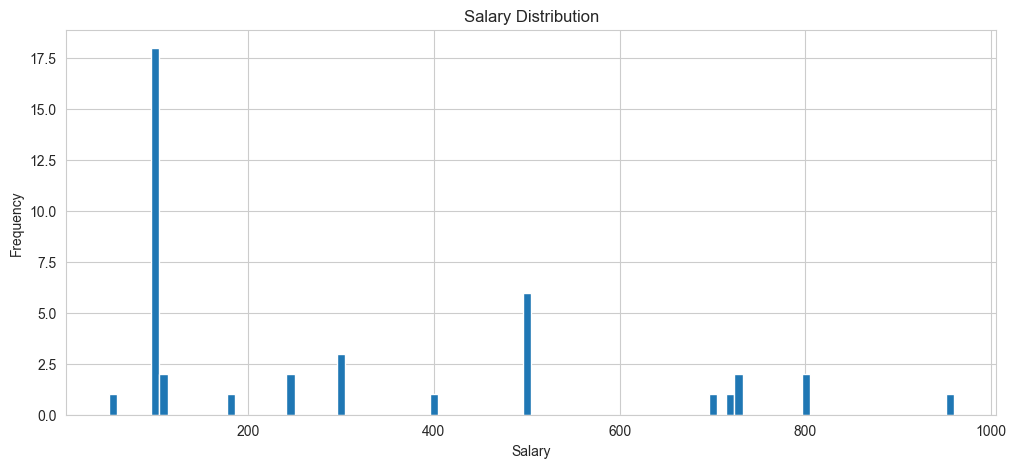

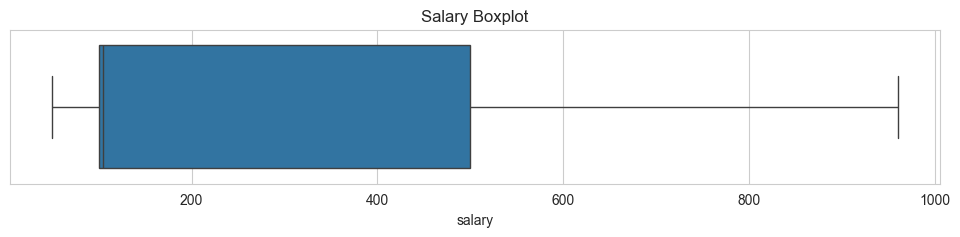

In [5]:
## 5.a Salary analysis

salary_numeric = (
    df['salary']
    .astype(str)
    .str.replace(',', '', regex=False)
)

salary_numeric = pd.to_numeric(
    salary_numeric,
    errors='coerce'
)

print('Salary descriptive statistics:')
display(salary_numeric.describe())

# =========================================================
# Histogram
# =========================================================

plt.figure(figsize=FIGSIZE)

plt.hist(
    salary_numeric.dropna(),
    bins=100
)

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

# =========================================================
# Boxplot
# =========================================================

plt.figure(figsize=(12, 2))

sns.boxplot(
    x=salary_numeric.dropna()
)

plt.title('Salary Boxplot')

plt.show()


### b. Cột experience_level

Experience level distribution:


experience_level
3 năm       175905
1 năm       161459
2 năm        93194
4 năm        83516
5 năm        39438
             ...  
3-7 năm          1
3-6 năm          1
4-6 năm          1
5-10 năm         1
2-5 năm          1
Name: count, Length: 161, dtype: int64

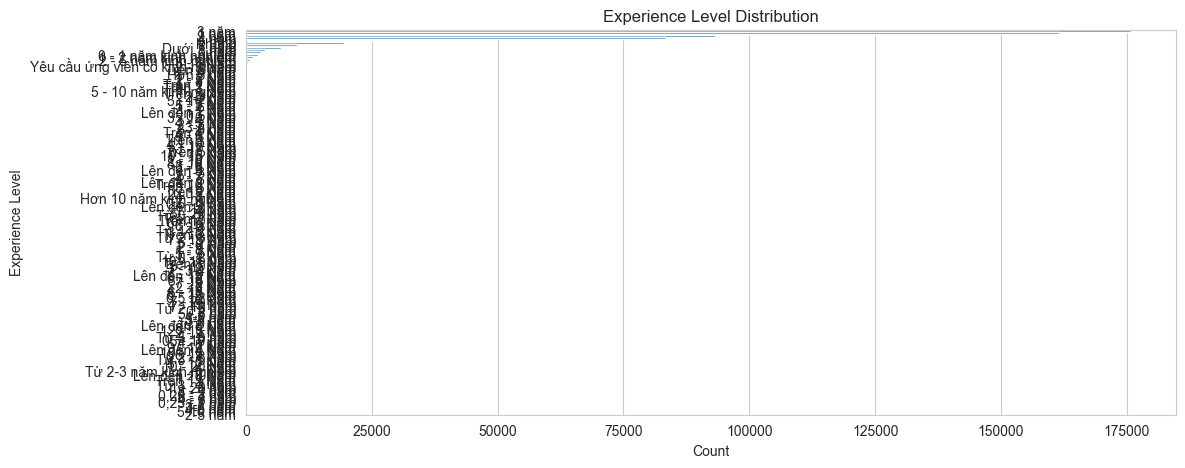

In [6]:
## 5.b Experience level

print('Experience level distribution:')
display(df['experience_level'].value_counts(dropna=False))

plt.figure(figsize=FIGSIZE)

order = (
    df['experience_level']
    .value_counts()
    .index
)

sns.countplot(
    data=df,
    y='experience_level',
    order=order
)

plt.title('Experience Level Distribution')
plt.xlabel('Count')
plt.ylabel('Experience Level')

plt.show()

### c. Cột job_position

Top job positions:


job_position
Nhân viên                   466921
Chưa cập nhật                47812
Trưởng nhóm                  28642
Trưởng phòng                 19189
Cộng tác viên                13559
Nhân Viên                    11984
Giám đốc                      9789
Chuyên gia                    3472
Thực Tập Sinh                  558
Trưởng Nhóm                    470
NaN                            447
Trưởng Nhóm / Giám Sát         375
Quản Lý                        369
Thực tập sinh                  330
Sinh Viên/ Thực Tập Sinh       292
Kỹ thuật viên / Kỹ sư          243
Trưởng nhóm / Giám sát         229
Quản lý / Trưởng phòng         214
Quản Lý / Giám Sát             180
Mới đi làm                     180
Name: count, dtype: int64

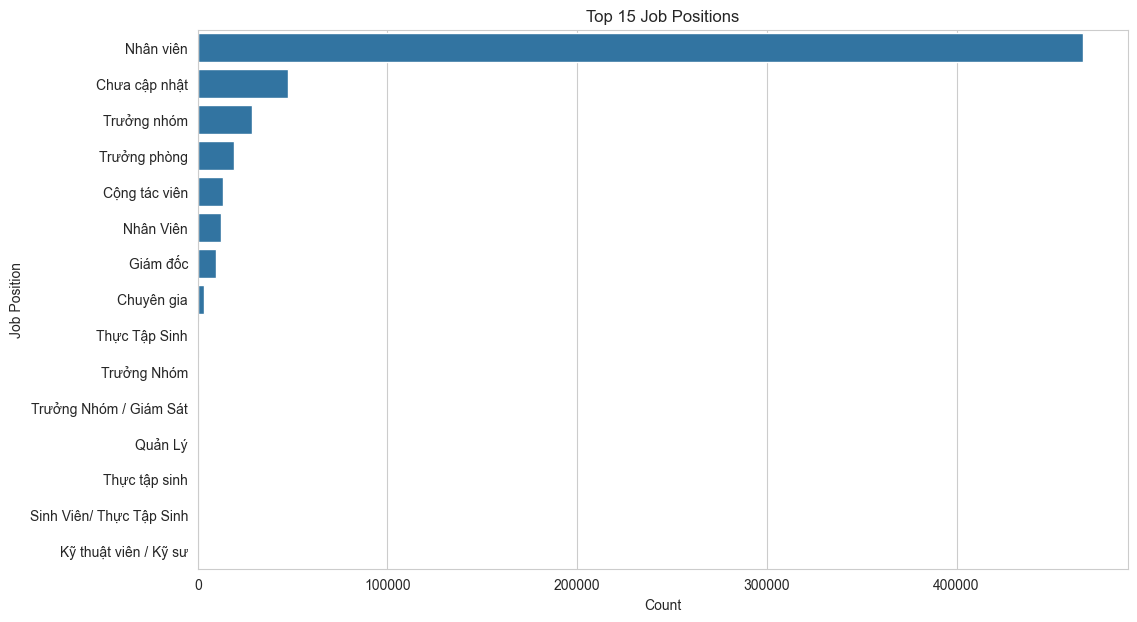

In [7]:
## 5.c Job position

print('Top job positions:')
display(df['job_position'].value_counts(dropna=False).head(20))

plt.figure(figsize=(12, 7))

top_positions = (
    df['job_position']
    .value_counts()
    .head(TOP_K)
)

sns.barplot(
    x=top_positions.values,
    y=top_positions.index
)

plt.title(f'Top {TOP_K} Job Positions')
plt.xlabel('Count')
plt.ylabel('Job Position')

plt.show()

### d. Cột education_level

Education level distribution:


education_level
Không                 210188
Cao đẳng              146725
Đại học                95863
Trung cấp              93885
Trung học              49689
Chứng chỉ               9270
Cử nhân                 1171
Khác                      52
Kỹ sư                     32
Bằng cấp liên quan         3
Name: count, dtype: int64

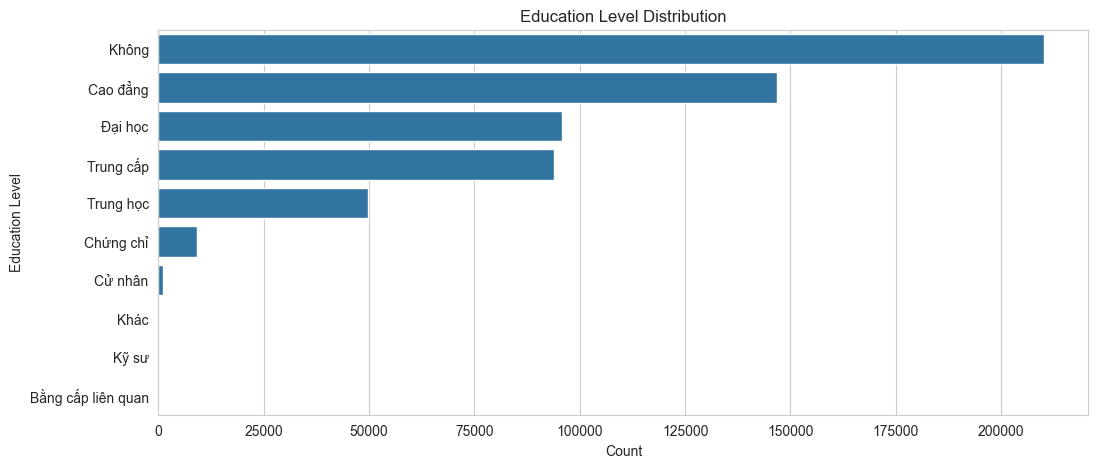

In [8]:
## 5.d Education level

print('Education level distribution:')
display(df['education_level'].value_counts(dropna=False))

plt.figure(figsize=FIGSIZE)

order = (
    df['education_level']
    .value_counts()
    .index
)

sns.countplot(
    data=df,
    y='education_level',
    order=order
)

plt.title('Education Level Distribution')
plt.xlabel('Count')
plt.ylabel('Education Level')

plt.show()

### e. Cột job_type

Job type distribution:


job_type
Toàn thời gian                                      559365
Thực tập                                             17278
Khác                                                  9222
Bán thời gian                                         7209
Remote                                                5850
Thời vụ                                               3222
Chưa xác định                                         3049
Không                                                  783
Hợp đồng                                               549
Theo ca                                                201
Toàn thời gian, Bán thời gian                           49
Freelance                                               44
Toàn thời gian, Thực tập                                34
Toàn thời gian, Thời vụ                                  7
Toàn thời gian, Bán thời gian, Remote                    4
Bán thời gian, Remote                                    3
Bán thời gian, Thực tập                        

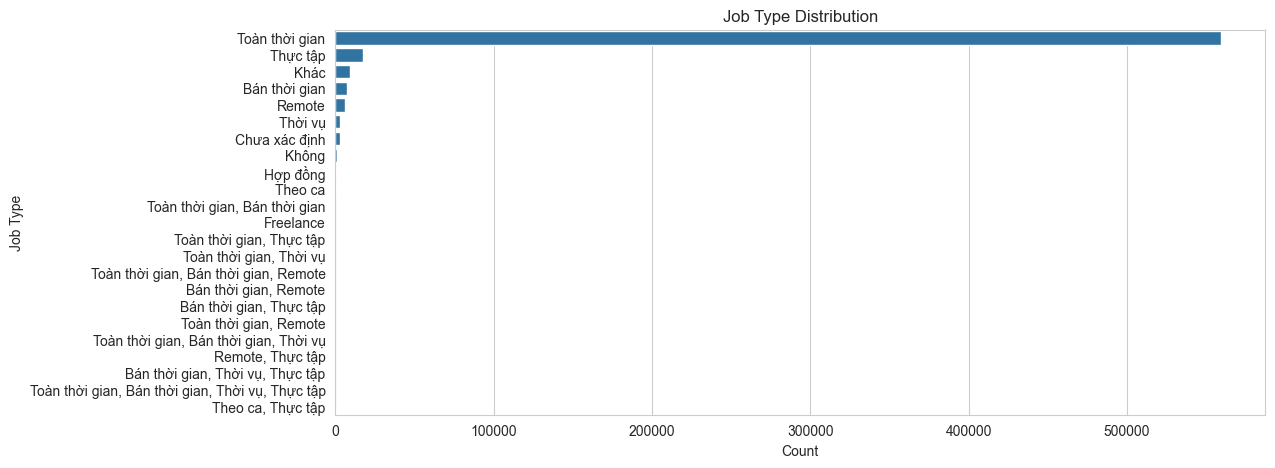

In [9]:
## 5.e Job type

print('Job type distribution:')
display(df['job_type'].value_counts(dropna=False))

plt.figure(figsize=FIGSIZE)

order = (
    df['job_type']
    .value_counts()
    .index
)

sns.countplot(
    data=df,
    y='job_type',
    order=order
)

plt.title('Job Type Distribution')
plt.xlabel('Count')
plt.ylabel('Job Type')

plt.show()

### f. Cột location

Top locations:


location
Tầng 8, tầng 9, tầng 10 tòa nhà số 24C đường Phan Đăng Lưu, Phường Gia Định, TP Hồ Chí Minh, Việt Nam                                6534
Hồ Chí Minh                                                                                                                          6244
Hà Nội                                                                                                                               5398
198 Hoàng Văn Thụ Phường 9 Phú Nhuận                                                                                                 1634
15, Lê Thánh Tôn, Phường Bến Nghé, Quận 1                                                                                            1049
Số 601 đường Nguyễn Văn Linh, Phường An Tảo, Thành phố Hưng Yên, Tỉnh Hưng Yên, Việt Nam                                              983
Tầng G, 8 và 10 Tòa nhà Phụ Nữ, số 20 Nguyễn Đăng Giai, Phường Thảo Điền, Thành phố Thủ Đức, TP Hồ Chí Minh                           895
Cụm công nghiệp Lai Xá - 

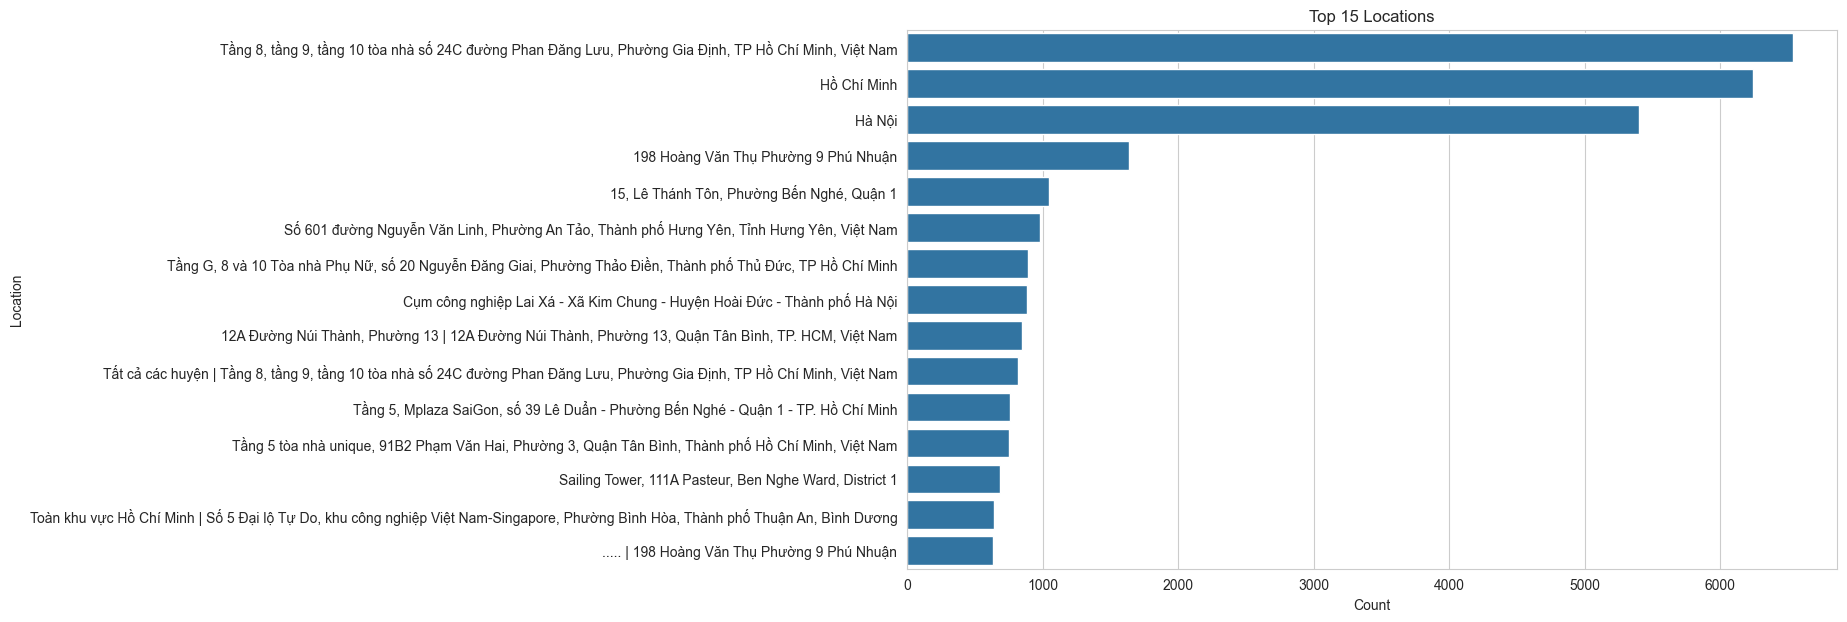

In [10]:
## 5.f Location

print('Top locations:')
display(df['location'].value_counts(dropna=False).head(20))

top_locations = (
    df['location']
    .value_counts()
    .head(TOP_K)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title(f'Top {TOP_K} Locations')
plt.xlabel('Count')
plt.ylabel('Location')

plt.show()

### g. Cột year

**Mục tiêu:**

- Kiểm tra phân phối dữ liệu theo năm
- Quan trọng để justify stratified split

Year distribution:


year
2022    111033
2023    129674
2024    159049
2025    160386
2026     46736
Name: count, dtype: int64

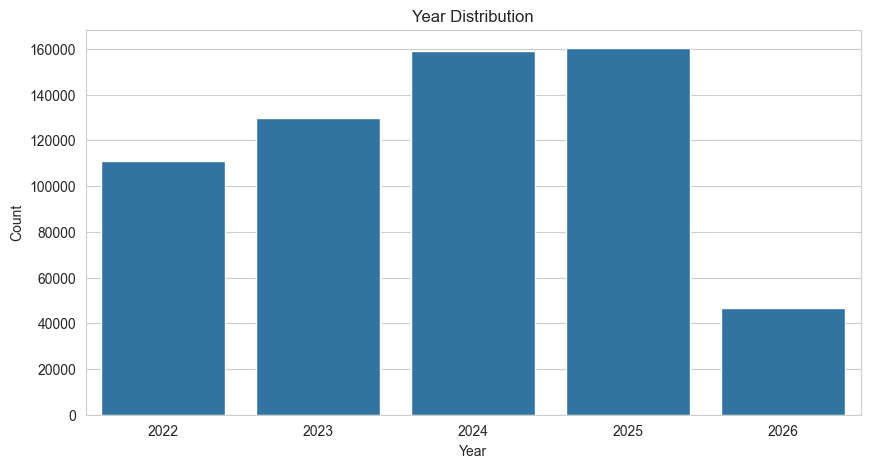


Year percentage (%):


year
2022    18.30
2023    21.37
2024    26.21
2025    26.43
2026     7.70
Name: proportion, dtype: float64

In [11]:
## 5.g Year distribution

year_counts = (
    df['year']
    .value_counts()
    .sort_index()
)

print('Year distribution:')
display(year_counts)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=year_counts.index.astype(str),
    y=year_counts.values
)

plt.title('Year Distribution')
plt.xlabel('Year')
plt.ylabel('Count')

plt.show()

# =========================================================
# Year percentage
# =========================================================

year_pct = (
    df['year']
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)

print('\nYear percentage (%):')
display(year_pct)

## 6. Stratified split 90/10

Stratify theo `year` để train/test có cùng tỉ lệ các năm — quan trọng vì dataset chứa data đa năm và mỗi năm có thể có distribution khác nhau.

In [12]:
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
    stratify=df[STRATIFY_COL],
)

print(f'Train: {len(train_df):,} rows  ({len(train_df) / len(df) * 100:.2f}%)')
print(f'Test : {len(test_df):,} rows  ({len(test_df) / len(df) * 100:.2f}%)')
print()

compare = pd.DataFrame({
    'full_pct' : df[STRATIFY_COL].value_counts(normalize=True).sort_index() * 100,
    'train_pct': train_df[STRATIFY_COL].value_counts(normalize=True).sort_index() * 100,
    'test_pct' : test_df[STRATIFY_COL].value_counts(normalize=True).sort_index() * 100,
}).round(2)

print('Phân phối year sau khi split (%):')
print(compare.to_string())

Train: 546,190 rows  (90.00%)
Test : 60,688 rows  (10.00%)

Phân phối year sau khi split (%):
      full_pct  train_pct  test_pct
year                               
2022     18.30      18.30     18.30
2023     21.37      21.37     21.37
2024     26.21      26.21     26.21
2025     26.43      26.43     26.43
2026      7.70       7.70      7.70


## 7. Export CSV

- `encoding='utf-8'` để giữ tiếng Việt có dấu.
- `index=False` để không thêm cột index không cần thiết.
- CSV cho 600k dòng sẽ khá lớn (~1 GB cho train) — chấp nhận được vì format được yêu cầu.

In [13]:
%%time
OUT_TRAIN_CSV.parent.mkdir(parents=True, exist_ok=True)

# Parquet — dùng cho pipeline downstream (nhanh hơn 5-10x)
train_df.to_parquet(OUT_TRAIN_PARQUET, compression='snappy', index=False)
test_df.to_parquet (OUT_TEST_PARQUET,  compression='snappy', index=False)
print(f'✓ Saved train parquet → {OUT_TRAIN_PARQUET}  ({OUT_TRAIN_PARQUET.stat().st_size / 1024**2:.1f} MB)')
print(f'✓ Saved test  parquet → {OUT_TEST_PARQUET}   ({OUT_TEST_PARQUET.stat().st_size / 1024**2:.1f} MB)')

# CSV — artifact để nộp bài (đúng yêu cầu đồ án)
train_df.to_csv(OUT_TRAIN_CSV, index=False, encoding='utf-8')
test_df.to_csv (OUT_TEST_CSV,  index=False, encoding='utf-8')
print(f'✓ Saved train CSV → {OUT_TRAIN_CSV}  ({OUT_TRAIN_CSV.stat().st_size / 1024**2:.1f} MB)')
print(f'✓ Saved test  CSV → {OUT_TEST_CSV}   ({OUT_TEST_CSV.stat().st_size / 1024**2:.1f} MB)')

✓ Saved train parquet → ../data/raw/raw_data_train.parquet  (456.5 MB)
✓ Saved test  parquet → ../data/raw/raw_data_test.parquet   (50.6 MB)
✓ Saved train CSV → ../data/raw/raw_data_train.csv  (1053.5 MB)
✓ Saved test  CSV → ../data/raw/raw_data_test.csv   (117.1 MB)
CPU times: user 18.7 s, sys: 735 ms, total: 19.4 s
Wall time: 19.6 s


## 8. Sanity check

Đọc lại CSV để xác nhận shape, dtype, encoding tiếng Việt vẫn đúng.

In [14]:
train_reload = pd.read_csv(OUT_TRAIN_CSV, encoding='utf-8')
test_reload  = pd.read_csv(OUT_TEST_CSV,  encoding='utf-8')

print(f'Train reload: {train_reload.shape}  (expected {train_df.shape})')
print(f'Test  reload: {test_reload.shape}   (expected {test_df.shape})')
assert train_reload.shape == train_df.shape
assert test_reload.shape  == test_df.shape

print('\nSample 3 dòng train (kiểm tra tiếng Việt):')
print(train_reload[['job_title', 'location', 'salary']].head(3).to_string(index=False))

Train reload: (546190, 14)  (expected (546190, 14))
Test  reload: (60688, 14)   (expected (60688, 14))

Sample 3 dòng train (kiểm tra tiếng Việt):
                                                job_title                                                                                                                            location                     salary
      [Quảng Bình - Vincom Quảng Bình] Tổ Trưởng Cửa Hàng                           Vincom Quảng Bình | Tầng 26, Tòa nhà CII Tower, số 152 Điện Biên Phủ, Phường Thạnh Mỹ Tây, TP Hồ Chí Minh  7.900.000 - 8.700.000 VND
  Assistant Manager Of Administration And Human Resources        40 đường 40 KDC Vạn Phúc, phường Hiệp Bình Phước | 40 Đường số 40, Phường Hiệp Bình Phước, Thành phố Thủ Đức, TP Hồ Chí Minh                      0 VND
Nhân Viên CSKH (Tư Vấn Chốt Đơn) - Lương Từ 10Tr - Quận 2 Số 12 đường 7A, Phường An Phú | Số 15 đường 54, phường Thảo Điền | Số 6 Đường 31C, Phường An Phú, Thành phố Thủ Đức, TP Hồ Chí Minh 6.000.000 - 

## 9. Tóm tắt

**Đã làm**:
1. Load `data/raw/data.parquet` (606,878 dòng).
2. Split 90/10 stratified theo `year`, `random_state=42`.
3. Export 2 file CSV: `raw_data_train.csv`, `raw_data_test.csv` (UTF-8, không index).
4. Verify bằng cách đọc lại CSV.

**Next**: chạy `02_1_clean_data.ipynb` để clean — notebook đó cần được sửa lại để đọc từ `raw_data_train.csv` + `raw_data_test.csv` và xuất ra `clean_data_train.csv` + `clean_data_test.csv`.